# Melbourne House Price Prediction 
### Predicting the price of a house with Linear Regression (Regression project)
*Midterm project, CS-300 Introduction to Machine Learning*

## .Importing the libraries 
*The tools I need are Pandas and NumPy for the data, and scikit-learn for preprocessing, models, and scores.*

In [1]:
# Libraries 
import pickle 
import pandas  as pd 
import numpy as np 

from  sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer 
from sklearn.preprocessing import OneHotEncoder, StandardScaler 
from  sklearn.decomposition import PCA
from sklearn.linear_model import LinearRegression 
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error, root_mean_squared_error


## 1. Data and Features

In [2]:
import pandas as pd 
import numpy as np 
mel = pd.read_csv('../dataset/Melbourne_housing.csv', low_memory = False)
mel.head()

,Suburb,Address,Rooms,Type,Method,SellerG,Date,Distance,Postcode,Bedroom,...,Landsize,BuildingArea,YearBuilt,CouncilArea,Latitude,Longtitude,Regionname,Propertycount,ParkingArea,Price
0,Abbotsford,68 Studley St,2,h,SS,Jellis,3/9/2016,2.5,3067.0,2.0,...,126.0,inf,NaN,Yarra City Council,-37.8014,144.9958,Northern Metropolitan,4019.0,Carport,NaN
1,Airport West,154 Halsey Rd,3,t,PI,Nelson,3/9/2016,13.5,3042.0,3.0,...,303.0,225,2016.0,Moonee Valley City Council,-37.7180,144.8780,Western Metropolitan,3464.0,Detached Garage,840000.0
2,Albert Park,105 Kerferd Rd,2,h,S,hockingstuart,3/9/2016,3.3,3206.0,2.0,...,120.0,82,1900.0,Port Phillip City Council,-37.8459,144.9555,Southern Metropolitan,3280.0,Attached Garage,1275000.0
3,Albert Park,85 Richardson St,2,h,S,Thomson,3/9/2016,3.3,3206.0,2.0,...,159.0,inf,NaN,Port Phillip City Council,-37.8450,144.9538,Southern Metropolitan,3280.0,Indoor,1455000.0
4,Alphington,30 Austin St,3,h,SN,McGrath,3/9/2016,6.4,3078.0,3.0,...,174.0,122,2003.0,Darebin City Council,-37.7818,145.0198,Northern Metropolitan,2211.0,Parkade,NaN


In [3]:
# Fix the spelling of Latitude 

mel = mel.rename(columns = { 'Latitude' : 'Lattitude'})
mel.head(1)

,Suburb,Address,Rooms,Type,Method,SellerG,Date,Distance,Postcode,Bedroom,...,Landsize,BuildingArea,YearBuilt,CouncilArea,Lattitude,Longtitude,Regionname,Propertycount,ParkingArea,Price
0,Abbotsford,68 Studley St,2,h,SS,Jellis,3/9/2016,2.5,3067.0,2.0,...,126.0,inf,NaN,Yarra City Council,-37.8014,144.9958,Northern Metropolitan,4019.0,Carport,NaN


In [4]:
# Summary numbers (count, mean, min, max ) of the number columns 
mel.info()

<class 'pandas.DataFrame'>
RangeIndex: 34857 entries, 0 to 34856
Data columns (total 22 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Suburb         34857 non-null  str    
 1   Address        34857 non-null  str    
 2   Rooms          34857 non-null  int64  
 3   Type           34857 non-null  str    
 4   Method         34857 non-null  str    
 5   SellerG        34857 non-null  str    
 6   Date           34857 non-null  str    
 7   Distance       34856 non-null  float64
 8   Postcode       34856 non-null  float64
 9   Bedroom        26640 non-null  float64
 10  Bathroom       26631 non-null  float64
 11  Car            26129 non-null  float64
 12  Landsize       23047 non-null  float64
 13  BuildingArea   13760 non-null  str    
 14  YearBuilt      15551 non-null  float64
 15  CouncilArea    34854 non-null  str    
 16  Lattitude      26881 non-null  float64
 17  Longtitude     26881 non-null  float64
 18  Regionname     34

In [5]:
mel.columns

Index(['Suburb', 'Address', 'Rooms', 'Type', 'Method', 'SellerG', 'Date',
       'Distance', 'Postcode', 'Bedroom', 'Bathroom', 'Car', 'Landsize',
       'BuildingArea', 'YearBuilt', 'CouncilArea', 'Lattitude', 'Longtitude',
       'Regionname', 'Propertycount', 'ParkingArea', 'Price'],
      dtype='str')

## Independent and dependent variables 
*Choosing the columns model will use as input (features) and the column Price is the label.*

In [6]:
# Drop some columns and keep price
a = mel.drop(columns = [ 'Address', 'Method', 'SellerG', 'Date', 'Postcode', 'CouncilArea', 'Lattitude', 'Longtitude', 'Propertycount', 'ParkingArea', 'Price' ])
print(a.columns)
p =  mel['Price']


Index(['Suburb', 'Rooms', 'Type', 'Distance', 'Bedroom', 'Bathroom', 'Car',
       'Landsize', 'BuildingArea', 'YearBuilt', 'Regionname'],
      dtype='str')


In [7]:
# Concatenate features and label (price)

mel= pd.concat ([a, p], axis = 1).copy()
mel.head()

,Suburb,Rooms,Type,Distance,Bedroom,Bathroom,Car,Landsize,BuildingArea,YearBuilt,Regionname,Price
0,Abbotsford,2,h,2.5,2.0,1.0,1.0,126.0,inf,NaN,Northern Metropolitan,NaN
1,Airport West,3,t,13.5,3.0,2.0,1.0,303.0,225,2016.0,Western Metropolitan,840000.0
2,Albert Park,2,h,3.3,2.0,1.0,0.0,120.0,82,1900.0,Southern Metropolitan,1275000.0
3,Albert Park,2,h,3.3,2.0,1.0,0.0,159.0,inf,NaN,Southern Metropolitan,1455000.0
4,Alphington,3,h,6.4,3.0,2.0,1.0,174.0,122,2003.0,Northern Metropolitan,NaN


In [8]:
# 12 columns 
len(mel.columns)

12

In [9]:
mel.dtypes

Suburb              str
Rooms             int64
Type                str
Distance        float64
Bedroom         float64
Bathroom        float64
Car             float64
Landsize        float64
BuildingArea        str
YearBuilt       float64
Regionname          str
Price           float64
dtype: object

In [10]:
mel.describe()

,Rooms,Distance,Bedroom,Bathroom,Car,Landsize,YearBuilt,Price
count,34857.000000,34856.000000,26640.000000,26631.000000,26129.000000,23047.000000,15551.000000,2.724700e+04
mean,3.031012,11.184929,3.084647,1.624798,1.728845,593.598993,1965.289885,1.050173e+06
std,0.969933,6.788892,0.980690,0.724212,1.010771,3398.841946,37.328178,6.414671e+05
min,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1196.000000,8.500000e+04
25%,2.000000,6.400000,2.000000,1.000000,1.000000,224.000000,1940.000000,6.350000e+05
50%,3.000000,10.300000,3.000000,2.000000,2.000000,521.000000,1970.000000,8.700000e+05
75%,4.000000,14.000000,4.000000,2.000000,2.000000,670.000000,2000.000000,1.295000e+06
max,16.000000,48.100000,30.000000,12.000000,26.000000,433014.000000,2106.000000,1.120000e+07


## 2. Data Cleaning 
*Look for dirty values and missing values before training the model.*
## 2.1  duplicated rows 

*Checking if the same row appears more than once.*

In [11]:
print(mel.loc[mel.duplicated().sum()])

Suburb                   Keilor East
Rooms                              4
Type                               h
Distance                        12.8
Bedroom                          3.0
Bathroom                         1.0
Car                              1.0
Landsize                       622.0
BuildingArea                     126
YearBuilt                     1965.0
Regionname      Western Metropolitan
Price                       845000.0
Name: 1028, dtype: object


## 2.2 Missing values 
*Checking every column one by one: how many values are missing, and are the numbers realistic?*

In [12]:
missingvles = mel.isnull().sum()
missing_perecnt = (missingvles/len(mel)* 100 ).round(3)
pd.DataFrame ({'missing values': missingvles, 'percent': missing_perecnt}).sort_values('percent', ascending = True)

,missing values,percent
Suburb,0,0.000
Rooms,0,0.000
Type,0,0.000
Regionname,0,0.000
Distance,1,0.003
Price,7610,21.832
Bedroom,8217,23.573
Bathroom,8226,23.599
Car,8728,25.039
Landsize,11810,33.881


In [13]:
# columns with numbers 
mel.select_dtypes(include = 'number').columns

Index(['Rooms', 'Distance', 'Bedroom', 'Bathroom', 'Car', 'Landsize',
       'YearBuilt', 'Price'],
      dtype='str')

## 1_Checking Room column

In [14]:
mel['Rooms'].unique()

array([ 2,  3,  4,  5,  1,  6,  7,  8, 10,  9, 12, 16])

In [15]:
mel['Rooms'].value_counts(dropna = False)

Rooms
3     15084
2      8332
4      7956
5      1737
1      1479
6       204
7        32
8        19
10        6
9         4
12        3
16        1
Name: count, dtype: int64

## 2_Checking Distance column

In [16]:
mel['Distance'].value_counts(dropna= False)

Distance
11.2    1420
13.8     681
9.2      665
7.8      662
10.5     660
        ... 
30.6       1
22.9       1
33.0       1
31.4       1
32.6       1
Name: count, Length: 216, dtype: int64

In [17]:
mel['Distance'].unique()

array([ 2.5, 13.5,  3.3,  6.4, 13.8, 11.1,  6.3,  5.9, 11. , 12.2, 10.5,
        6.6,  9.7,  9.2, 13. , 13.9, 13.1, 10.8, 11.2, 10.7,  5.2, 11.8,
       11.7,  7.8,  9. ,  3.2, 11.4,  8.9,  8.1,  9.3, 13.6,  3.4,  1.6,
       10.3,  8.5,  7.7,  8. ,  9.4,  5.8,  3.5,  4.4, 12.1, 13.7, 14.5,
        4.6,  7.9, 15. , 12.8,  4.2,  5.6,  7.5,  6.2,  7.4,  8.7,  2.8,
        4.1,  6.9, 14.6,  8.4,  2.3,  5.5, 11.5, 14.7,  2.6,  9.9,  3.8,
        4.5,  8.8,  2.1,  1.2,  6.1, 12.6, 13.3,  6.5, 14.9,  1.9,  5.1,
        7. ,  9.1,  9.5,  1.8,  1.5,  9.8, 12.4, 10.6,  8.2, 10.4, 14. ,
       12.5,  5.3, 12.7, 10.9,  3. ,  5.7, 15.5,  4.3, 10.2, 16.5, 23.2,
       17.3, 35.2, 13.4, 25. , 16.1,  4. , 14.8, 10.1, 17.9, 17.5, 16.7,
        3.6, 43.4,  6.7, 20.6, 34.7, 23. , 24.7, 21.8, 22.2, 14.3, 25.9,
        1.3, 27. , 18. ,  7.2, 36.9, 19.6, 28.8, 24.8, 15.4, 38. , 45.9,
       12.9,  7.3, 20.4, 32.3, 45.2, 21.3, 16. , 18.4, 12.3,  5.4, 25.2,
       16.3, 33.8, 31.7, 29.8, 20. , 17.2, 16.2, 21

##  3_Checking NaN values in Bedroom column


In [18]:
mel['Bedroom'].unique()

array([ 2.,  3.,  5., nan,  4.,  1.,  6.,  7.,  0., 20.,  8., 30.,  9.,
       12., 10., 16.])

In [19]:
mel['Bedroom'].value_counts(dropna = False)

Bedroom
3.0     11881
NaN      8217
4.0      6348
2.0      5777
5.0      1427
1.0       966
6.0       168
7.0        30
0.0        17
8.0        13
9.0         5
10.0        4
20.0        1
30.0        1
12.0        1
16.0        1
Name: count, dtype: int64

## 4_Checking NaN values in Bathroom column


In [20]:
mel['Bathroom'].unique()

array([ 1.,  2.,  3., nan,  4.,  5.,  0., 12.,  7.,  8.,  6.,  9.])

In [21]:
mel.loc[mel['Bathroom'] == 0, ['Bathroom']]

,Bathroom
247,0.0
1125,0.0
1265,0.0
1440,0.0
1443,0.0
1554,0.0
1694,0.0
2038,0.0
2327,0.0
2552,0.0


In [22]:
mel['Bathroom'].value_counts(dropna = False)

Bathroom
1.0     12969
2.0     11064
NaN      8226
3.0      2181
4.0       269
5.0        77
0.0        46
6.0        16
7.0         4
8.0         3
12.0        1
9.0         1
Name: count, dtype: int64

## 5_Checking NaN values in Car column


In [23]:
mel['Car'].unique()

array([ 1.,  0.,  4.,  2.,  6., nan,  3.,  7.,  5.,  9.,  8., 10., 12.,
       11., 26., 18.])

In [24]:
mel['Car'].value_counts(dropna = False)

Car
2.0     12214
1.0      9164
NaN      8728
0.0      1631
3.0      1606
4.0      1161
5.0       151
6.0       140
7.0        25
8.0        23
10.0        6
9.0         3
11.0        2
12.0        1
26.0        1
18.0        1
Name: count, dtype: int64

## 6_Checking NaN values in  Landsize column


In [25]:
mel['Landsize'].unique()

array([ 126.,  303.,  120., ..., 2193., 1357., 9833.], shape=(1685,))

In [26]:
mel['Landsize'].value_counts(dropna = False)

Landsize
NaN       11810
0.0        2437
650.0       204
697.0       123
585.0        97
          ...  
1751.0        1
1390.0        1
2193.0        1
1357.0        1
9833.0        1
Name: count, Length: 1685, dtype: int64

In [27]:
# Checking double time  total na vlues rows 
mel.loc[mel['Landsize'].isna(), ['Landsize']]

,Landsize
11,NaN
17,NaN
20,NaN
32,NaN
33,NaN
...,...
34847,NaN
34849,NaN
34850,NaN
34852,NaN


## 7_Checking the YearBuilt column NA values in the dataset 


In [28]:
mel['YearBuilt'].sort_values().unique()

array([1196., 1800., 1820., 1830., 1850., 1854., 1855., 1856., 1857.,
       1860., 1862., 1863., 1868., 1869., 1870., 1871., 1872., 1875.,
       1876., 1877., 1879., 1880., 1881., 1883., 1884., 1885., 1886.,
       1887., 1888., 1889., 1890., 1891., 1892., 1893., 1894., 1895.,
       1896., 1897., 1898., 1899., 1900., 1901., 1902., 1903., 1904.,
       1905., 1906., 1907., 1908., 1909., 1910., 1911., 1912., 1913.,
       1914., 1915., 1916., 1917., 1918., 1919., 1920., 1921., 1922.,
       1923., 1924., 1925., 1926., 1927., 1928., 1929., 1930., 1931.,
       1932., 1933., 1934., 1935., 1936., 1937., 1938., 1939., 1940.,
       1941., 1942., 1943., 1945., 1946., 1947., 1948., 1949., 1950.,
       1951., 1952., 1953., 1954., 1955., 1956., 1957., 1958., 1959.,
       1960., 1961., 1962., 1963., 1964., 1965., 1966., 1967., 1968.,
       1969., 1970., 1971., 1972., 1973., 1974., 1975., 1976., 1977.,
       1978., 1979., 1980., 1981., 1982., 1983., 1984., 1985., 1986.,
       1987., 1988.,

*1196 and 2106 are  not realistic years, so converting them into na is better for the model*

## 8_Checking missing values for BuildingArea  


In [29]:
mel['BuildingArea'].isnull().sum()

np.int64(21097)

In [30]:
mel['BuildingArea'].unique()

<ArrowStringArray>
[    'inf',     '225',      '82',     '122',     '263',     '242',     '108',
     '251',     '117', 'missing',
 ...
     '703',  '129.92',  '436.64',    '43.7',   '113.6',   '66.32',   '35.64',
    '61.6',   '388.5',     '672']
Length: 743, dtype: str

In [31]:
mel['BuildingArea'].value_counts(dropna = False)

BuildingArea
NaN      21097
120        185
100        161
110        159
130        153
         ...  
66.32        1
35.64        1
61.6         1
388.5        1
672          1
Name: count, Length: 743, dtype: int64

In [32]:
# Checking how many 'missing' rows there are  
mel.loc[mel['BuildingArea'] == 'missing', ['BuildingArea']], mel.loc[mel['BuildingArea'] == 'inf', ['BuildingArea']]


(     BuildingArea
 11        missing
 12        missing
 15        missing
 20        missing
 31        missing
 32        missing
 33        missing
 34        missing
 35        missing
 806       missing
 5786      missing,
     BuildingArea
 0            inf
 3            inf
 6            inf
 17           inf
 18           inf
 19           inf
 333          inf)

## 9_Checking missing values for BuildingArea  


In [33]:
mel['BuildingArea'].unique()

<ArrowStringArray>
[    'inf',     '225',      '82',     '122',     '263',     '242',     '108',
     '251',     '117', 'missing',
 ...
     '703',  '129.92',  '436.64',    '43.7',   '113.6',   '66.32',   '35.64',
    '61.6',   '388.5',     '672']
Length: 743, dtype: str

In [34]:
mel['BuildingArea'].value_counts(dropna= False)

BuildingArea
NaN      21097
120        185
100        161
110        159
130        153
         ...  
66.32        1
35.64        1
61.6         1
388.5        1
672          1
Name: count, Length: 743, dtype: int64

In [35]:
mel.columns

Index(['Suburb', 'Rooms', 'Type', 'Distance', 'Bedroom', 'Bathroom', 'Car',
       'Landsize', 'BuildingArea', 'YearBuilt', 'Regionname', 'Price'],
      dtype='str')

## 10_Checking missing values for Suburb  


In [36]:
mel['Suburb'].unique()

<ArrowStringArray>
[        'Abbotsford',       'Airport West',        'Albert Park',
         'Alphington',             'Altona',       'Altona North',
           'Armadale',         'Ascot Vale',          'Ashburton',
            'Ashwood',
 ...
         'Yarra Glen', 'Beaconsfield Upper',      'Menzies Creek',
             'Darley',             'Silvan',          'Eynesbury',
     'Gisborne South',            'croydon',            'Monbulk',
           'viewbank']
Length: 351, dtype: str

In [37]:
mel['Suburb'].value_counts(dropna = False)

Suburb
Reservoir         844
Bentleigh East    583
Richmond          552
Glen Iris         491
Preston           485
                 ... 
Menzies Creek       1
Eynesbury           1
croydon             1
Monbulk             1
viewbank            1
Name: count, Length: 351, dtype: int64

## 11_Checking missing values for Type   column


In [38]:
mel['Type'].unique()

<ArrowStringArray>
['h', 't', 'u']
Length: 3, dtype: str

In [39]:
mel['Type'].value_counts(dropna= False)

Type
h    23980
u     7297
t     3580
Name: count, dtype: int64

## 12_Checking missing values for Regionname  column


In [40]:
mel['Regionname'].unique()

<ArrowStringArray>
[     'Northern Metropolitan',       'Western Metropolitan',
      'Southern Metropolitan',       'Eastern Metropolitan',
 'South-Eastern Metropolitan',           'Eastern Victoria',
          'Northern Victoria',           'Western Victoria']
Length: 8, dtype: str

In [41]:
mel['Regionname'].value_counts(dropna = False)

Regionname
Southern Metropolitan         11836
Northern Metropolitan          9560
Western Metropolitan           6799
Eastern Metropolitan           4377
South-Eastern Metropolitan     1739
Eastern Victoria                228
Northern Victoria               203
Western Victoria                115
Name: count, dtype: int64

### **Investigating all columns for the model is done**

In [42]:
mel.select_dtypes(include ='str').columns, mel.select_dtypes(include ='number').columns


(Index(['Suburb', 'Type', 'BuildingArea', 'Regionname'], dtype='str'),
 Index(['Rooms', 'Distance', 'Bedroom', 'Bathroom', 'Car', 'Landsize',
        'YearBuilt', 'Price'],
       dtype='str'))

# Choosing final label and features

In [43]:
feature_cols = mel.columns[:-1].tolist()
data= mel[feature_cols + ["Price"]].copy()

In [44]:
data.columns

Index(['Suburb', 'Rooms', 'Type', 'Distance', 'Bedroom', 'Bathroom', 'Car',
       'Landsize', 'BuildingArea', 'YearBuilt', 'Regionname', 'Price'],
      dtype='str')

## 2.3  Missing values 
*Rows without Price are removed. Text values and impossible numbers are turned into NaN, so the imputer can fill them later.*

In [45]:
data.describe().T[['min', 'max']]

,min,max
Rooms,1.0,16.0
Distance,0.0,48.1
Bedroom,0.0,30.0
Bathroom,0.0,12.0
Car,0.0,26.0
Landsize,0.0,433014.0
YearBuilt,1196.0,2106.0
Price,85000.0,11200000.0


In [46]:
data.isnull().sum()

Suburb              0
Rooms               0
Type                0
Distance            1
Bedroom          8217
Bathroom         8226
Car              8728
Landsize        11810
BuildingArea    21097
YearBuilt       19306
Regionname          0
Price            7610
dtype: int64

In [47]:
# errors= 'coerce' turns anything that is not a number into NaN.
data['BuildingArea'] = pd.to_numeric(data['BuildingArea'], errors='coerce')
data['BuildingArea'] = data['BuildingArea'].replace([np.inf, -np.inf], np.nan)

 *Cannot train or test a model with included rows that have missing values. Also, filling the target with the mean or median would be making up the answer. Removing rows is the best alternative method.*

In [48]:
# Price is the answer we want to predict, so rows without it are removed.
print('Rows before removing missing Price:', len(data))
data = data.dropna(subset=['Price'])
print('Rows after removing missing Price :', len(data))
 

Rows before removing missing Price: 34857
Rows after removing missing Price : 27247


In [49]:
# Impossible values become NaN, so the imputer fills them later.
data.loc[data['Landsize'] > 50000, 'Landsize'] = np.nan
data.loc[(data['BuildingArea'] <= 0) | (data['BuildingArea'] > 1000), 'BuildingArea'] = np.nan
data.loc[(data['YearBuilt'] < 1800) | (data['YearBuilt'] > 2026), 'YearBuilt'] = np.nan
data.loc[data['Bedroom'] > 10, 'Bedroom'] = np.nan
data.loc[data['Bathroom'] > 8, 'Bathroom'] = np.nan
data.loc[data['Car'] > 10, 'Car'] = np.nan

In [50]:
data['BuildingArea'].describe(
    percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
)

count    10586.000000
mean       151.361075
std         84.558651
min          1.000000
25%        100.000000
50%        133.000000
75%        182.000000
90%        249.000000
95%        300.000000
99%        458.450000
max        999.000000
Name: BuildingArea, dtype: float64

In [51]:
# Rooms has no missing values, so the few houses with more than 10 rooms are removed.
data = data[data['Rooms'] <= 10]
print('Rows after cleaning:', len(data))
print(data.isnull().sum())

Rows after cleaning: 27244
Suburb              0
Rooms               0
Type                0
Distance            1
Bedroom          6441
Bathroom         6447
Car              6825
Landsize         9268
BuildingArea    16659
YearBuilt       15162
Regionname          0
Price               0
dtype: int64


##  3.  Defining Independent (X) and  dependent (y)

In [52]:
X = data[feature_cols]
y = data["Price"]
X.shape, y.shape

((27244, 11), (27244,))

In [53]:
X.columns

Index(['Suburb', 'Rooms', 'Type', 'Distance', 'Bedroom', 'Bathroom', 'Car',
       'Landsize', 'BuildingArea', 'YearBuilt', 'Regionname'],
      dtype='str')

In [54]:
# convert the specificcolumns's floats into integers  to see values clearly in the dataset
inte_cols = ['Rooms', 'Bedroom', 'Bathroom', 'Car', 'YearBuilt']

X [inte_cols] = X [inte_cols].astype('Int64')

In [55]:
X.head()

,Suburb,Rooms,Type,Distance,Bedroom,Bathroom,Car,Landsize,BuildingArea,YearBuilt,Regionname
1,Airport West,3,t,13.5,3,2,1,303.0,225.0,2016,Western Metropolitan
2,Albert Park,2,h,3.3,2,1,0,120.0,82.0,1900,Southern Metropolitan
3,Albert Park,2,h,3.3,2,1,0,159.0,NaN,<NA>,Southern Metropolitan
5,Alphington,4,h,6.4,3,2,4,853.0,263.0,1930,Northern Metropolitan
6,Alphington,3,h,6.4,3,2,2,208.0,NaN,2013,Northern Metropolitan


In [56]:
len(X.columns)

11

#  4. Train & Test split 

In [57]:
# Model selection

X_train, X_test, y_train, y_test = train_test_split(X,y, test_size =0.2, shuffle = True, random_state = 43)


In [58]:
X_train.shape, y_train.shape

((21795, 11), (21795,))

In [59]:
X_test.shape,y_test.shape

((5449, 11), (5449,))

## 4.1 Outliers: IQR rule after the split


In [60]:

X_train_orig = X_train.copy()

cap_cols = ['Rooms', 'Distance', 'Bedroom', 'Bathroom', 'Car', 'Landsize', 'BuildingArea']
cap_limits = {}    

print("Handling outliers in the house features (limits from the training data only)...")
for col in cap_cols:
    X_train[col] = X_train[col].astype(float)
    X_test[col] = X_test[col].astype(float)

    Q1 = X_train[col].quantile(0.25)
    Q3 = X_train[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 3 * IQR    
    upper_bound = Q3 + 3 * IQR
    cap_limits[col] = (lower_bound, upper_bound)

    outliers = len(X_train[(X_train[col] < lower_bound) | (X_train[col] > upper_bound)])

    print(f"  {col}: {outliers} outliers detected")
    print(f"    Range before: [{X_train[col].min():.2f}, {X_train[col].max():.2f}]")

   
    X_train[col] = X_train[col].clip(lower_bound, upper_bound)
    X_test[col] = X_test[col].clip(lower_bound, upper_bound)
    print(f"    Range after: [{X_train[col].min():.2f}, {X_train[col].max():.2f}]")

Handling outliers in the house features (limits from the training data only)...
  Rooms: 0 outliers detected
    Range before: [1.00, 10.00]
    Range after: [1.00, 10.00]
  Distance: 207 outliers detected
    Range before: [0.00, 48.10]
    Range after: [0.00, 36.80]
  Bedroom: 0 outliers detected
    Range before: [0.00, 10.00]
    Range after: [0.00, 10.00]
  Bathroom: 12 outliers detected
    Range before: [0.00, 8.00]
    Range after: [0.00, 5.00]
  Car: 115 outliers detected
    Range before: [0.00, 10.00]
    Range after: [0.00, 5.00]
  Landsize: 220 outliers detected
    Range before: [0.00, 44500.00]
    Range after: [0.00, 1996.00]
  BuildingArea: 107 outliers detected
    Range before: [1.00, 999.00]
    Range after: [1.00, 424.00]


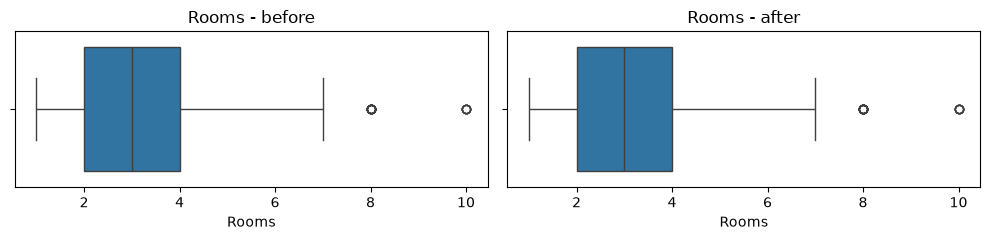

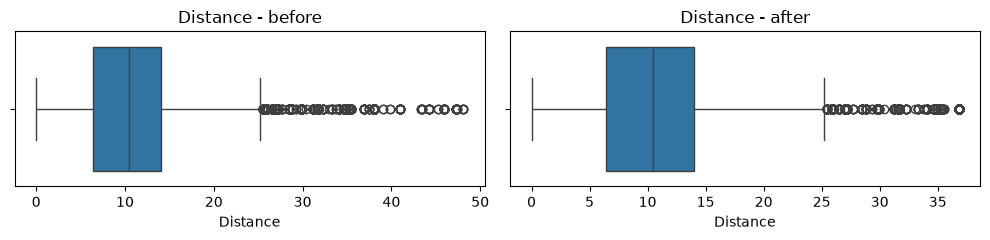

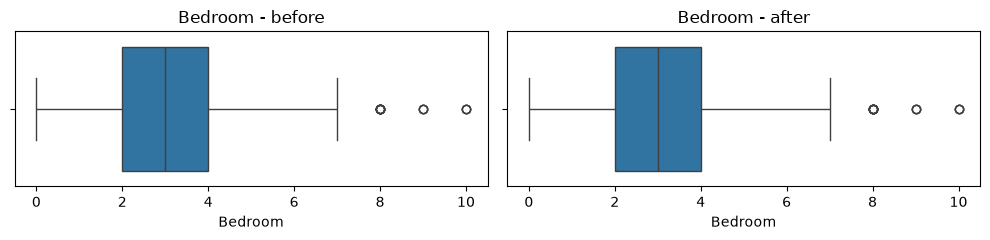

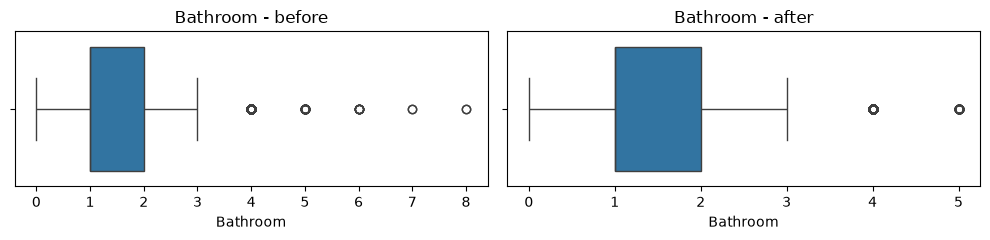

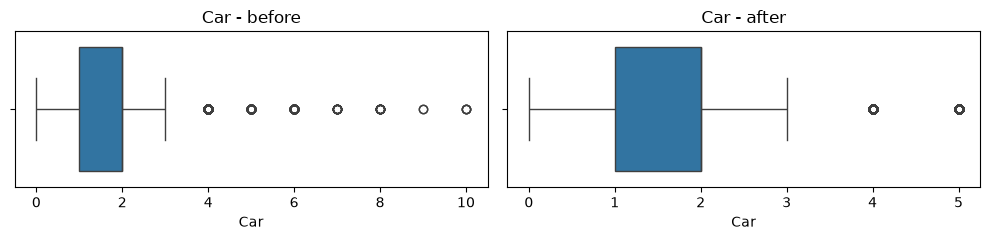

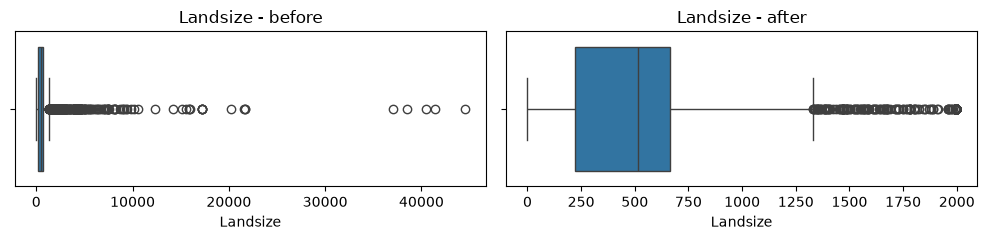

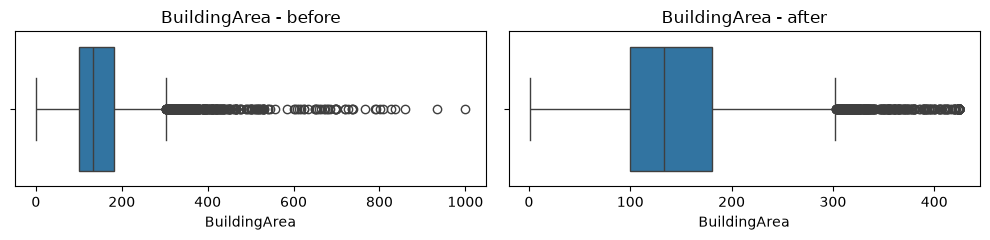

In [61]:
import seaborn as sns
import matplotlib.pyplot as plt

for col in cap_cols:
    plt.figure(figsize=(10, 2.5))

    plt.subplot(1, 2, 1)
    sns.boxplot(x=X_train_orig[col].astype(float))
    plt.title(col + ' - before')

    plt.subplot(1, 2, 2)
    sns.boxplot(x=X_train[col])
    plt.title(col + ' - after')

    plt.tight_layout()
    plt.show()

## 5. Data Transformation (Preprocessing)
*Changing text into numbers with one-hot encoding) and filling the missing values (imputation) and scaling the numbers (StandardScaler)*

## 5.1 Number  columns and text columns

In [62]:
# Category cols and numerical columns 
cat_cols = X.select_dtypes (include = ['object', 'string']).columns
num_cols = X.select_dtypes (include = ['number']).columns

In [63]:
X[cat_cols].isnull().sum()

Suburb        0
Type          0
Regionname    0
dtype: int64

In [64]:
X[num_cols].isnull().sum()

Rooms               0
Distance            1
Bedroom          6441
Bathroom         6447
Car              6825
Landsize         9268
BuildingArea    16659
YearBuilt       15162
dtype: int64

## 5.2 The preprocessing tools 
*Each tool is saved in a variable to use it inside the pipelines*

In [65]:
# Instance names of classes
num_imputer = SimpleImputer(strategy='median')

std = StandardScaler()

cat_imputer = SimpleImputer(strategy='most_frequent') 

onehot = OneHotEncoder(sparse_output=False, handle_unknown='ignore')

## 5.3 Numbers: median imputation, then StandardScaler
*Missing numbers are filled with the median, then every number column is scaled to mean 0 and standard deviation 1.*

In [66]:
# numbers: fill missing with median, then scale
num_stages = Pipeline([
    ('imputer', num_imputer),
    ('scaling', std)
])
num_stages

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('imputer', ...), ('scaling', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"strategy strategy: str or Callable, default='mean'The imputation strategy.- If ""mean"", then replace missing values using the mean along each column. Can only be used with numeric data.- If ""median"", then replace missing values using the median along each column. Can only be used with numeric data.- If ""most_frequent"", then replace missing using the most frequent value along each column. Can be used with strings or numeric data. If there is more than one such value, only the smallest is returned.- If ""constant"", then replace missing values with fill_value. Can be used with strings or numeric data.- If an instance of Callable, then replace missing values using the scalar statistic returned by running the callable over a dense 1d array containing non-missing values of each column... versionadded:: 0.20 strategy=""constant"" for fixed value imputation... versionadded:: 1.5 strategy=callable for custom value imputation.",'median'
,"missing_values missing_values: int, float, str, np.nan, None or pandas.NA, default=np.nanThe placeholder for the missing values. All occurrences of`missing_values` will be imputed. For pandas' dataframes withnullable integer dtypes with missing values, `missing_values`can be set to either `np.nan` or `pd.NA`.",nan
,"fill_value fill_value: str or numerical value, default=NoneWhen strategy == ""constant"", `fill_value` is used to replace alloccurrences of missing_values. For string or object data types,`fill_value` must be a string.If `None`, `fill_value` will be 0 when imputing numericaldata and ""missing_value"" for strings or object data types.",None
,"copy copy: bool, default=TrueIf True, a copy of X will be created. If False, imputation willbe done in-place whenever possible. Note that, in the following cases,a new copy will always be made, even if `copy=False`:- If `X` is not an array of floating values;- If `X` is encoded as a CSR matrix;- If `add_indicator=True`.",True
,"add_indicator add_indicator: bool, default=FalseIf True, a :class:`MissingIndicator` transform will stack onto outputof the imputer's transform. This allows a predictive estimatorto account f

## 5.4 Text: most frequent imputation, then one-hot encoding
*Missing text is filled with the most frequent value, then each category becomes its own 0/1 column. Both parts are joined in one ColumnTransformer.*

In [67]:
# Category_cols: Fill missing values with the most frequent, then one-hot encode
cat_stages = Pipeline([
    ('imputer', cat_imputer),
    ('encoding', onehot)
])
 
preprocessing = ColumnTransformer([
    ('numcolumns', num_stages, num_cols),
    ('catcolumns', cat_stages, cat_cols)
])

preprocessing

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numcolumns', ...), ('catcolumns', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``

# 6. Feature Engineering: two models
*Model 1 uses feature extraction (PCA, 10 components) and Model 2 uses all the columns. Then I compare them.*

* **Pipeline1**: preprocessing, PCA (dimensionality reduction)  and LinearRegression  for **fewer columns**
* **pipeline2**: preprocessing & LinearRegression  **all columns**

In [68]:
# Model 1: with PCA 
# The model tools, each one saved in a variable
# (two separate LinearRegression objects, so Model 1 and Model 2 do not share one)


reduce_cols = PCA(n_components =10)
lr1 = LinearRegression()
lr2 = LinearRegression()



# Model 1: PCA (10 components)
pipeline1 = Pipeline([
    ('preprocessing', preprocessing),
    ('selection', reduce_cols),
    ('modelling', lr1)
])

 
# Model 2: all columns
pipeline2 = Pipeline([
    ('preprocessing', preprocessing),
    ('modelling', lr2)
])
 

## 6.1 Model 1: PCA + Linear Regression
*Train the model, then check R2 , MAE, MSE and RMSE on the training and testing data.*

###  Fit X_train & y_train

In [69]:
# train mdoel 1 
pipeline1.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessing', ...), ('selection', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](11,)","['Suburb','Rooms','Type',...,'BuildingArea','YearBuilt','Regionname']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,11
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numcolumns', ...), ('catcolumns', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. 

###  Checking prediction results with  ground truths and training truths  

In [70]:
test_pred1 = pipeline1.predict(X_test)
test_r2_1 = r2_score (y_test, test_pred1)
test_mae_1 = mean_absolute_error (y_test, test_pred1)
test_mse_1 = mean_squared_error (y_test, test_pred1)
test_rmse_1 = root_mean_squared_error(y_test, test_pred1)

train_pred1 = pipeline1.predict(X_train)
train_r2_1 = r2_score (y_train, train_pred1)
train_mae_1 = mean_absolute_error (y_train, train_pred1)
train_mse_1 = mean_squared_error (y_train, train_pred1)
train_rmse_1 = root_mean_squared_error(y_train, train_pred1)

print("\nModel 1 (PCA, 10 components)")

print(f"Training R2: {train_r2_1:.3f} MAE: {train_mae_1:.0f} MSE: {train_mse_1:.3f} RMSE: {train_rmse_1:,.0f}")
print(f"Testing R2: {test_r2_1:.3f} MAE: {test_mae_1:.0f} MSE: {test_mse_1:.3f} RMSE: {test_rmse_1:,.0f}")



Model 1 (PCA, 10 components)
Training R2: 0.577 MAE: 277133 MSE: 172394475791.025 RMSE: 415,204
Testing R2: 0.572 MAE: 277631 MSE: 179777473190.500 RMSE: 424,002


# Model  2 : Train & Test

## 6.2 Model 2: all columns + Linear Regression
*Train the model, then check R2, MAE, MSE and RMSE on the training and testing data.*

In [71]:
# Train Model 2 
pipeline2.fit(X_train, y_train)


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessing', ...), ('modelling', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](11,)","['Suburb','Rooms','Type',...,'BuildingArea','YearBuilt','Regionname']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,11
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numcolumns', ...), ('catcolumns', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This 

In [72]:
# Train Model 2 , then prediction and scores with  testing and training data
test_pred2 = pipeline2.predict(X_test)
test_r2_2 = r2_score(y_test, test_pred2)
test_mae_2 = mean_absolute_error(y_test, test_pred2)
test_mse_2 = mean_squared_error(y_test, test_pred2)
test_rmse_2 = np.sqrt(test_mse_2)
 
train_pred2 = pipeline2.predict(X_train)
train_r2_2 = r2_score(y_train, train_pred2)
train_mae_2 = mean_absolute_error(y_train, train_pred2)
train_mse_2 = mean_squared_error(y_train, train_pred2)
train_rmse_2 = np.sqrt(train_mse_2)
 
print('\nModel 2 (all columns)')
print(f'Training  R2: {train_r2_2:.3f}  MAE: {train_mae_2:,.0f}  MSE: {train_mse_2:,.3f}   RMSE: {train_rmse_2:,.0f}')
print(f'Testing   R2: {test_r2_2:.3f}  MAE: {test_mae_2:,.0f}    MSE: {test_mse_2:,.3f}   RMSE: {test_rmse_2:,.0f}')


Model 2 (all columns)
Training  R2: 0.678  MAE: 229,525  MSE: 131,508,081,518.069   RMSE: 362,640
Testing   R2: 0.675  MAE: 229,013    MSE: 136,703,704,805.985   RMSE: 369,735


# 7. Trying different numbers of components for Model 1
'n_components' is the number of new columns PCA creates. I try the values 5, 6, 7 and some other bigger ones and then compare them with Model 2 (all columns, no PCA)

In [73]:
# 7. Different n_components for Model 1
print('Trying different n_components for PCA')
for n in [5, 6, 7, 10, 50, 100, 200]:
    model = Pipeline([
        ('preprocessing', preprocessing),
        ('dimensionality_reduction', PCA(n_components=n)),
        ('modelling', LinearRegression())
    ])
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    r2 = r2_score(y_test, pred)
    mae = mean_absolute_error(y_test, pred)
    print(f'n_components = {n:3d}   R2 = {r2:.3f}   MAE = {mae:,.0f}')

Trying different n_components for PCA
n_components =   5   R2 = 0.418   MAE = 330,923
n_components =   6   R2 = 0.423   MAE = 330,263
n_components =   7   R2 = 0.423   MAE = 329,786
n_components =  10   R2 = 0.572   MAE = 277,631
n_components =  50   R2 = 0.619   MAE = 254,212
n_components = 100   R2 = 0.640   MAE = 247,266
n_components = 200   R2 = 0.668   MAE = 232,304


*When I used fewer components, the R2 score was lower (5 components: 0.418...). As I kept more components, the performance improved, but Model 2, which uses all columns, was still the best (R2  = 0.675). The Suburb column creates many one-hot columns, so squeezing everything into a few components loses the suburb information. Model 2 (all columns) is better, so I chose it as my final model.*

# 8. Evaluation: reading R2, MAE and RMSE
How stable and reliable is the final model? I ran cross-validation to check the R2 scores across different folds. 

In [74]:
# Cross-validation score of Model 2 (5 folds)
cv2 = cross_val_score(
    pipeline2,
    X_train,
    y_train,
    cv=5,
    scoring='r2'
)
cv2

array([0.67958231, 0.66790219, 0.68522477, 0.66962432, 0.63817656])

## 8.1 Evaluating MAE and RMSE against median home values.
*Checking MAE and RMSE relative to a typical home price to see how significant our prediction errors are*

In [75]:
#test 
min_price = y_test.min()
max_price = y_test.max()
mean_price = y_test.mean()
median_price = y_test.median()

print(f"Minimum price: ${min_price:,.0f}")
print(f"Maximum price: ${max_price:,.0f}")
print(f"Mean price: ${mean_price:,.0f}")
print(f"Median price: ${median_price:,.0f}")

Minimum price: $145,000
Maximum price: $11,200,000
Mean price: $1,048,055
Median price: $868,000


## 8.2 Where does the model struggle most 

In [76]:
# Where are the big errors? Average error for each price range

errors = pd.DataFrame({'real_price': y_test, 'error': (y_test - test_pred2).abs()})
errors['price_range'] = pd.cut(errors['real_price'],
                               [0, 600000, 900000, 1300000, 2000000, 100000000],
                               labels=['under 600k', '600k-900k', '0.9M-1.3M', '1.3M-2M', 'over 2M'])
print(errors.groupby('price_range')['error'].agg(['count', 'mean']).round(0))

             count      mean
price_range                 
under 600k    1182  192683.0
600k-900k     1724  182595.0
0.9M-1.3M     1226  189888.0
1.3M-2M        948  217602.0
over 2M        369  721558.0


## 8.3 Cross Validation 

In [77]:
# 8. Cross-validation (5 folds, training data only)
kfold = KFold(n_splits=5, shuffle=True, random_state=42)
cv1 = cross_val_score(pipeline1, X_train, y_train, cv=kfold, scoring='r2')
cv2 = cross_val_score(pipeline2, X_train, y_train, cv=kfold, scoring='r2')
 
print('\nCross validation R2')
print('Model 1 (PCA):', cv1.round(2), 'mean =', cv1.mean().round(2))
print('Model 2 (all)   :', cv2.round(2), 'mean =', cv2.mean().round(2))


Cross validation R2
Model 1 (PCA): [0.59 0.58 0.57 0.56 0.58] mean = 0.58
Model 2 (all)   : [0.69 0.68 0.66 0.65 0.67] mean = 0.67


*After performing 5-fold cross-validation, Model 2 achieved a higher average R2 score of 0.67, compared with 0.58 for Model 1. Model 2  was also better in all five folds (0.65 to 0.69, against 0.56 to 0.59 for Model 1). So using all the columns gave clearly better results, and they were just as stable. Therefore, I decided to use Model 2 as my final model.*

In [78]:
# How big is the error compared with a typical house?
median_price = y_test.median()
print(f"Median house price (test set): ${median_price:,.0f}")
print(f"Model 2 MAE  : ${test_mae_2:,.0f}  = {test_mae_2 / median_price:.0%} of the median price")
print(f"Model 2 RMSE : ${test_rmse_2:,.0f}")
print(f"RMSE / MAE = {test_rmse_2 / test_mae_2:.2f}   (above 1 means some houses have large errors)")
print(f"Cross-validation R2: lowest {cv2.min():.3f}, highest {cv2.max():.3f}, gap {cv2.max() - cv2.min():.3f}")

Median house price (test set): $868,000
Model 2 MAE  : $229,013  = 26% of the median price
Model 2 RMSE : $369,735
RMSE / MAE = 1.61   (above 1 means some houses have large errors)
Cross-validation R2: lowest 0.651, highest 0.688, gap 0.037


## 9 Checking model and predictions with examples 

In [79]:
# 9. Final model: the better one Model2 
final_model = pipeline2

# Example 1: a house from the test set (the same row for the prediction and the real price)

one_house = X_test.iloc[[2022]]
predicted_price = final_model.predict(one_house)[0]
real_price = y_test.iloc[2022]
print(f'Predicted: ${predicted_price:,.0f}   Real: ${real_price:,.0f}')

Predicted: $889,065   Real: $840,000


In [80]:
# Example 2: a new house 
new_house = pd.DataFrame(
    [
        {
    'Suburb': 'Brighton', 'Rooms': 3, 'Type': 'h', 'Distance': 10.0, 'Bedroom': 3, 'Bathroom': 2, 'Car': 1,
    'Landsize': 400, 'BuildingArea': 160, 'YearBuilt': 1990,
    'Regionname': 'Southern Metropolitan'
}
    ]
)
print(f'New house: ${final_model.predict(new_house)[0]:,.0f}')


New house: $2,040,747


In [81]:
# Example 3: the first 10 houses of the test set with predicted price and real price
houses = X_test.head(10)
real_prices = y_test.head(10)

predicted_prices = final_model.predict(houses)

for i in range(10):
    print('House', i + 1)
    print(f'  Predicted: ${predicted_prices[i]:,.0f}  Real: ${real_prices.iloc[i]:,.0f}')

House 1
  Predicted: $1,688,354  Real: $1,270,000
House 2
  Predicted: $1,527,857  Real: $1,540,000
House 3
  Predicted: $2,999,404  Real: $2,580,000
House 4
  Predicted: $836,613  Real: $605,000
House 5
  Predicted: $1,134,550  Real: $986,000
House 6
  Predicted: $691,336  Real: $463,500
House 7
  Predicted: $372,317  Real: $588,000
House 8
  Predicted: $872,058  Real: $840,000
House 9
  Predicted: $910,778  Real: $790,000
House 10
  Predicted: $884,559  Real: $825,000


In [82]:
# Example 4: same house, but two values are unknown
house_with_gaps = new_house.copy()
house_with_gaps['BuildingArea'] = np.nan
house_with_gaps['YearBuilt'] = np.nan
print(f'With gaps: ${final_model.predict(house_with_gaps)[0]:,.0f}')

With gaps: $2,042,439


In [83]:

# Ex.5 Compare the predicted price with the real price 

row_index = 298

guess_house = X_test.iloc[[row_index]]

predicted_price = final_model.predict(guess_house)[0]

real_price = y_test.iloc[row_index]

print(f"Real: ${real_price:.2f}")
print(f"predicted: ${predicted_price:.2f}")



Real: $700000.00
predicted: $771977.37


# 10. Saving the model and cleaned data

In [84]:
# The clean data:  the training and testing data together
clean_data = pd.concat([X_train, X_test])
clean_data['Price'] = pd.concat([y_train, y_test])
clean_data = clean_data.sort_index()    # same order as the original data

# The values are learned from the training data only
num_imputer.fit(X_train[num_cols])
cat_imputer.fit(X_train[cat_cols])

clean_data[num_cols] = num_imputer.transform(clean_data[num_cols])
clean_data[cat_cols] = cat_imputer.transform(clean_data[cat_cols])

# Counts and the year are whole numbers, so they are saved as integers
# Distance, Landsize, BuildingArea and Price stay as decimal numbers
whole_cols = ['Rooms', 'Bedroom', 'Bathroom', 'Car', 'YearBuilt']
clean_data[whole_cols] = clean_data[whole_cols].round().astype(int)

print('Missing values after imputation:', clean_data.isnull().sum().sum())
print('Rooms in the clean data:', sorted(clean_data['Rooms'].unique().tolist()))

# Save the clean data and the final model for app.py
clean_data.to_csv('clean_data.csv', index=False)
with open('house_price_model.pkl', 'wb') as f:
    pickle.dump(final_model, f)

Missing values after imputation: 0
Rooms in the clean data: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10]
